# Baseline Model: Logistic Regression on TF-IDF

This notebook builds and evaluates our baseline model, a Logistic Regression classifier trained on TF-IDF features extracted from article text. As an inherently interpretable model, it serves as both a performance reference point and a transparent benchmark for comparing against more complex models in later notebooks.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score
)

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, get_split_tfidf, RANDOM_STATE
)

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing (NLP Pipeline)

Combine `title` + `text`, then apply: lowercasing → punctuation/special character removal → tokenization → stopword removal → lemmatization.

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization (Unigrams + Bigrams)

In [5]:
X, y, tfidf = get_tfidf_features(df)
print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


## 5. Train/Test Split

Fixed `random_state` and `stratify=y` ensure this exact split is reused identically across every model in this project.

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


## 6. Train Baseline Model: Logistic Regression

In [7]:
log_reg = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

## 7. Evaluation

Recall on the **Fake** class (`label_encoded = 1`) is the primary metric, per the project's trust-and-safety framing.

In [8]:
print(classification_report(y_test, y_pred, target_names=["fake", "real"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
print(f"Recall on Fake class (primary metric): {recall_fake:.4f}")

              precision    recall  f1-score   support

        fake       0.50      0.48      0.49      1989
        real       0.50      0.52      0.51      2011

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.50      0.50      0.50      4000

Recall on Fake class (primary metric): 0.5162


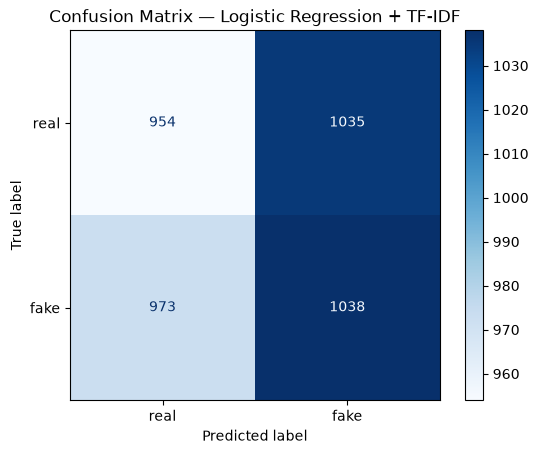

In [9]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["real", "fake"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix — Logistic Regression + TF-IDF")
plt.show()

- True Positive, correctly caught fake news article: 1,038
- False Negative, fake news article predicted as real: 973
- False Positive, real article predicted as fake: 1,035
- True Negative, correctly identified real article: 954

With a Fake-class recall of only ~52% (0.5167, display above) and an accuracy of 49.8%, the baseline model performs no better than random guessing. It catches barely half of the fake articles, which is far from reliable enough to support a trust-and-safety reviewer's decision, and it suggests weak linguistic signal in the text.

## 8. Interpretability: Coefficients → Odds Ratios

Since logistic regression is inherently interpretable, no post-hoc explanation method is needed. Coefficients map directly to specific words/n-grams.

In [10]:
feature_names = tfidf.get_feature_names_out()
coefficients = log_reg.coef_[0]

coef_df = pd.DataFrame({
    "term": feature_names,
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients)
})

print("Top 15 terms pushing toward FAKE (label_encoded=1):")
display(coef_df.sort_values("coefficient", ascending=False).head(15))

print("\nTop 15 terms pushing toward REAL (label_encoded=0):")
display(coef_df.sort_values("coefficient", ascending=True).head(15))

Top 15 terms pushing toward FAKE (label_encoded=1):


,term,coefficient,odds_ratio
528,particular,1.378175,3.967654
683,significant,1.323998,3.758418
464,model,1.249214,3.487601
736,stop,1.202394,3.328075
860,wrong,1.089866,2.973875
281,fire,1.067196,2.907215
263,far,1.062544,2.893723
36,animal,1.054010,2.869133
638,rich,1.036525,2.819401
17,agency,1.011494,2.749705



Top 15 terms pushing toward REAL (label_encoded=0):


,term,coefficient,odds_ratio
220,economy,-1.327948,0.265020
83,big,-1.291802,0.274775
77,behind,-1.154067,0.315352
523,painting,-1.105803,0.330945
618,reflect,-1.072386,0.342191
311,girl,-1.054595,0.348334
97,bring,-1.025730,0.358534
156,congress,-0.999243,0.368158
250,example,-0.995618,0.369495
707,son,-0.972673,0.378071


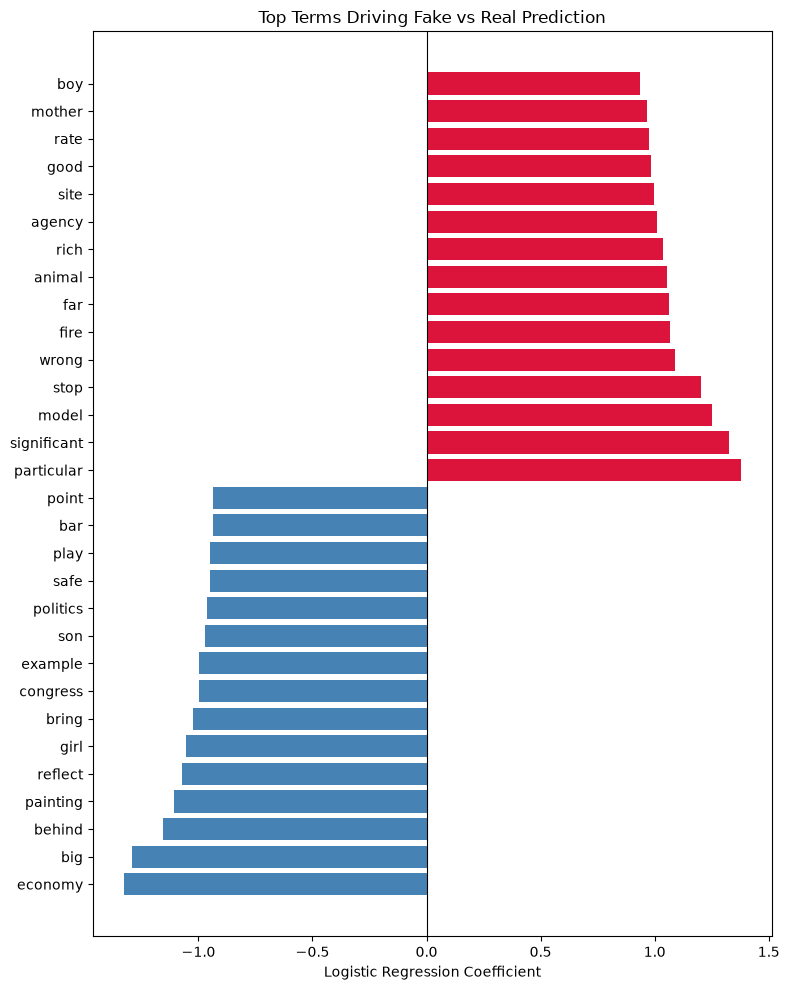

In [11]:
top_n = 15
top_real = coef_df.sort_values("coefficient", ascending=False).head(top_n)
top_fake = coef_df.sort_values("coefficient", ascending=True).head(top_n)
plot_df = pd.concat([top_fake, top_real])

plt.figure(figsize=(8, 10))
colors = ["steelblue" if c < 0 else "crimson" for c in plot_df["coefficient"]]
plt.barh(plot_df["term"], plot_df["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top Terms Driving Fake vs Real Prediction")
plt.xlabel("Logistic Regression Coefficient")
plt.tight_layout()
plt.show()

The top coefficients show no clear, interpretable linguistic pattern distinguishing fake from real articles. Terms pushing toward "fake" (e.g., *particular*, *significant*, *model*, *stop*, *wrong*) and terms pushing toward "real" (e.g., *economy*, *big*, *behind*, *painting*, *girl*) appear to be general-purpose or topic-related words rather than markers typically associated with fabricated reporting (e.g., sensational language, urgency cues, or emotionally charged phrasing).

This lack of a coherent linguistic story is consistent with the baseline's weak performance (Fake-class recall ≈ 52%, accuracy ≈ 50%). Rather than learning genuine stylistic differences between fake and real articles, the model appears to be picking up on weak, possibly incidental word-level associations in this particular dataset. Many article titles also read like loosely assembled word sequences rather than natural headlines, which raises the possibility that there is limited genuine linguistic signal separating the two classes to begin with.

This should be investigated further before concluding that complex models will perform meaningfully better, since if the underlying text genuinely lacks a learnable fake/real distinction, added model complexity is unlikely to resolve it.

The top terms in both directions are ordinary words, with no outlet names, bylines, or identifiers, so there is no obvious sign of a shortcut in the highest-weighted features.

### Why No LIME/SHAP/PDP/ICE for Logistic Regression

Logistic regression is inherently interpretable; its coefficients directly represent how each word/n-gram contributes to the prediction, with no approximation involved. Post-hoc explanation methods (LIME, SHAP, PDP, ICE) exist specifically to approximate or probe black-box models from the outside; applying them here would be redundant, since the model's own parameters already provide an exact, direct explanation. These methods become necessary starting with the next tier (Random Forest, XGBoost, LightGBM, SVM, Decision Trees), where the models are no longer transparent by design.